# 한글 글꼴 설치

In [ ]:
# (처음 한 번) 차트에 한글이 보이게 글꼴 설치
!apt-get -qq install -y fonts-nanum > /dev/null
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
    plt.rc("font", family="NanumGothic")
    print("한글 글꼴 준비 완료")
except FileNotFoundError:
    print("글꼴 설치 실패 → 차트의 한글이 네모로 보일 수 있어요")
plt.rcParams["axes.unicode_minus"] = False


# 드라이브 연결

In [ ]:
# 구글 드라이브 연결
from google.colab import drive
drive.mount('/content/drive')

# 운영체제(OS) 관련 기능 사용
import os

# 작업 위치를 step1 폴더로 이동
os.chdir('/content/drive/MyDrive/Colab Notebooks/Data_Analysis/DA_01')

# 현재 작업 위치 출력
print(os.getcwd())


Mounted at /content/drive
/content/drive/MyDrive/2_Data_analysis_1/step1


##### pip install statsmodels

##### statsmodels(스탯츠모델스) : 통계 분석과 회귀분석을 위한 파이썬 라이브러리1
```
Python
 ├─ NumPy          → 숫자/배열 계산
 ├─ pandas         → 데이터 처리
 ├─ SciPy          → 통계·과학 계산
 ├─ statsmodels    → 통계 분석·회귀분석⭐
 └─ scikit-learn   → 머신러닝

 ```
 ```
import statsmodels.formula.api as smf              # 통계분석 방식 선형회귀1

smf.ols()는 선형회귀 모델을 만드는 함수
model_lm = smf.ols(
    formula='weight ~ egg_weight',
    data=w2
)
병아리 무게(y)를 예측하는 직선
x와 y의 관계를 가장 잘 나타내는 직선 y = ax + b를 찾기 위한 모델을 준비하는 함수

OLS(Ordinary Least Squares) = 최소제곱법, 즉 오차의 제곱합이 가장 작아지는 직선을 찾는 방법


```
from sklearn.linear_model import LinearRegression  # 머신러닝 방식 선형회귀2 (뒤에나옴)

In [ ]:
%run start.py  # 여기에서 설치 했음

In [ ]:
# [수업 포인트] CSV 파일을 읽어서 DataFrame(표)으로 만드는 단계
w = pd.read_csv('data/chick004.csv')
w

,chick_nm,weight,egg_weight,movement,food
0,a01,140,65,146,14
1,a02,128,62,153,12
2,a03,140,65,118,13
3,a04,135,65,157,13
4,a05,145,69,157,13
5,a06,138,65,143,13
6,a07,125,61,110,11
7,a08,148,69,159,15
8,a09,133,64,133,11
9,a10,145,69,174,13


##### 30마리 병아리에 대해 몸무게와 성장에 관련될 만한 여러 정보를 기록한 데이터
| 속성           | 의미           |  예시 | 분석할 때 궁금한 것          |
| ------------ | ------------ | --: | -------------------- |
| `chick_nm`   | 병아리 번호       | a01 | 병아리 구분               |
| `weight`     | 병아리 몸무게      | 140 | **결과값**으로 볼 수 있음     |
| `egg_weight` | 태어나기 전 달걀 무게 |  65 | 달걀이 무거우면 병아리도 무거운가?  |
| `movement`   | 병아리 활동량      | 146 | 많이 움직이는 병아리가 더 무거운가? |
| `food`       | 먹이 섭취량       |  14 | 많이 먹으면 병아리가 더 무거운가?  |


In [ ]:
# [수업 포인트] info()로 열 이름, 자료형, 결측치 여부를 확인
w.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   chick_nm    30 non-null     object
 1   weight      30 non-null     int64 
 2   egg_weight  30 non-null     int64 
 3   movement    30 non-null     int64 
 4   food        30 non-null     int64 
dtypes: int64(4), object(1)
memory usage: 1.3+ KB


In [ ]:
w2 = w.iloc[ : , 1:5] # [행선택, 열선택]  / 모든 행 선택, 1-번열
w2

,weight,egg_weight,movement,food
0,140,65,146,14
1,128,62,153,12
2,140,65,118,13
3,135,65,157,13
4,145,69,157,13
5,138,65,143,13
6,125,61,110,11
7,148,69,159,15
8,133,64,133,11
9,145,69,174,13


# statsmodels의 OLS를 이용한 단순선형회귀분석1

## 회귀분석
- 회귀는 입력값(X)을 이용해 **숫자형 결과(y)**를 예측하는 방법이다.
- 기본 모양은 `y = ax + b`로 생각하면 이해하기 쉽다.
- `coef`는 X가 1 증가할 때 y가 얼마나 변하는지를 나타낸다.
- 학습용(train)과 테스트용(test)을 나누는 이유는 **처음 보는 데이터에서도 잘 맞는지 확인**하기 위해서이다.


In [ ]:
# 입력값과 결과값 사이의 관계를 직선/회귀식으로 학습
# 계란 무게로 병아리 무게를 예측하는 모델 만들기

# OLS = 최소제곱법 (오차를 최소로 만드는 직선 찾기)
                             # 종속변수 ,  독립변수
                             # 예측할 값 (종속변수, y), 입력값 (독립변수, x) weight는 egg_weight에 의해 결정된다

# 1. 모델 생성
# egg_weight(계란 무게)를 이용해서 weight(병아리 무게)를 예측
# 병아리 무게(y)를 예측하는 직선
model_lm = smf.ols(
     # 예측할 값 (종속변수, y), 입력값 (독립변수, x)
    formula='weight ~ egg_weight',
    data=w2
)

In [ ]:
# 2. 모델 학습
# 실제 데이터를 이용해 가장 오차가 작은 직선을 찾음
result_lm = model_lm.fit()

In [ ]:
# 표에서 coef(계수-기울기)만 보면 된다. Intercept (절편)-14.5475, egg_weight (기울기) 2.3371
# 최종식 : weight = 2.3371 × egg_weight - 14.5475
# 계란 무게가 1 증가하면 → 병아리 무게는 약 2.33 증가
# p-value : 0.000  0.05보다 작다 → 유의미하다 (중요한 변수), 계란 무게는 진짜 영향을 준다


# 3. 모델 결과 확인(결과 해석), 이 모델은 꽤 잘 맞는다, R-squared(설명력) 91.6% (엄청 높은 수준)
# 병아리 몸무게의 차이를 계란 무게라는 변수로 약 91.6% 설명하고 있다
# 0.7 이상 → 좋음, 0.9 이상 → 매우 좋음:이식은 엄청 좋은 모델


# summary() : 학습된 회귀모델의 분석 결과(R², 계수, p-value 등)를 표로 확인
print(result_lm.summary()) # 만든 회귀모델의 성적


                            OLS Regression Results                            
Dep. Variable:                 weight   R-squared:                       0.916
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     306.0
Date:                Mon, 07 Sep 2026   Prob (F-statistic):           1.32e-16
Time:                        06:43:04   Log-Likelihood:                -63.148
No. Observations:                  30   AIC:                             130.3
Df Residuals:                      28   BIC:                             133.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -14.5475      8.705     -1.671      0.1

```
Intercept   = -14.5475  → 절편
egg_weight =   2.3371  → 계수(coef) = 기울기
병아리무게=2.3371×계란무게−14.5475
y=ax+b
```
| 회귀분석         | `y = ax + b` | 현재 데이터     |
| ------------ | ------------ | ---------- |
| `weight`     | y            | 병아리 무게     |
| `egg_weight` | x            | 계란 무게      |
| **coef**     | **a (기울기)**  | **2.3371** |
| `Intercept`  | b (절편)       | -14.5475   |

```
coef = 기울기 = x가 1 증가할 때 y가 얼마나 변하는가

coef = 2.3371은
계란 무게가 1g 증가하면 병아리 무게가 평균 약 2.34g 증가한다.

| 볼 것                    |     현재 값 | 쉽게 말하면                                         |
| ---------------------- | -------: | ---------------------------------------------- |
| **R-squared**          |  `0.916` | 계란 무게로 병아리 무게를 **약 91.6% 설명**                  |
| **egg_weight coef**    | `2.3371` | 계란이 **1g 무거워질 때 병아리는 평균 약 2.34g 무거워짐**         |
| **egg_weight p-value** |  `0.000` | `0.05`보다 작음 → **계란 무게와 병아리 무게의 관계가 통계적으로 유의함** |


```
w2 데이터
   ↓
weight ~ egg_weight
병아리무게 ← 계란무게
   ↓
ols() : 어떤 관계를 학습할지 모델 준비
   ↓
fit() : 실제 데이터로 가장 적합한 직선 찾기
   ↓
summary() : 만들어진 회귀식과 분석 결과 확인

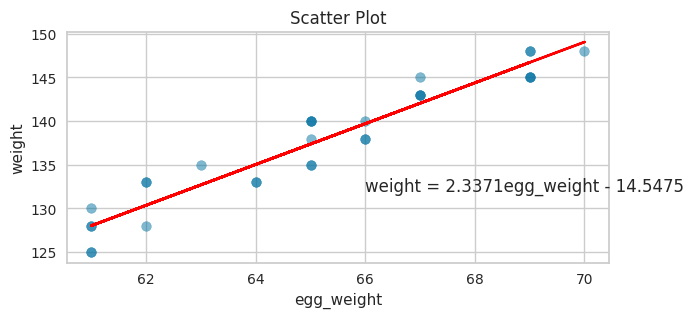

In [ ]:
# 종란무게에 따른 병아리무게 산점도
# 실제 데이터(점) + 예측 직선(빨간선)을 같이 그려서 관계를 확인하는 코드
# 계란 무게와 병아리 무게 관계를 점으로 찍고, 예측 직선을 같이 그린다
plt.figure(figsize = (7,3)) # 그래프 크기 (가로 7, 세로 3)

plt.scatter(w.egg_weight, w.weight, alpha = .5) #x축: 계란 무게, y축: 병아리 무게, 점으로 표시
plt.plot(w.egg_weight, w.egg_weight*2.3371 - 14.5475, color = 'red') # 우리가 만든 공식으로 그리기

plt.text(66, 132, 'weight = 2.3371egg_weight - 14.5475', fontsize = 12) # 그래프에 공식 써주기
plt.title('Scatter Plot')
plt.xlabel('egg_weight')
plt.ylabel('weight')
plt.show()

#점들 = 실제 데이터,  빨간선 = 예측 모델 : 점들이 선에 가까울수록 → 모델 잘 맞음


In [ ]:
"""
1 statsmodels : 공식 알려줌, matplotlib:그 공식으로 그림 그림
2 sklearn : 공식 만들고 계산까지 다 해줌 (모델이 알아서 계산)
statsmodels = 분석용, sklearn = 예측용
"""

## sklearn 라이브러리 LinearRegression 이용한 단순회귀분석2

In [ ]:
# 입력값과 결과값 사이의 관계를 직선/회귀식으로 학습
# sklearn으로 회귀모델 만들고 예측까지 하는 전체 흐름 : sklearn → 공식 + 예측
from sklearn.linear_model import LinearRegression

In [ ]:
x = w2[['egg_weight']]     ## 독립변수
y = w2['weight']           ## 종속변수, 하나의 열(Series)로 정의, 모델이 결과를 출력할 때도 1차원으로 반환함

In [ ]:
# 입력값과 결과값 사이의 관계를 직선/회귀식으로 학습

model = LinearRegression() # 선형회귀 모델 생성

model.fit(x, y) # 데이터를 학습, 가장 잘 맞는 직선(기울기와 절편)을 찾음

LinearRegression()

In [ ]:
# 계란 무게(x)를 넣었더니 → 모델이 병아리 무게를 계산해준 값
# x에 데이터가 여러 개 있기 때문, x = [계란1, 계란2, 계란3, ...] 결과도 y_pred = [예측1, 예측2, 예측3, ...]
# predict()는 공식에 넣어서 계산해주는 함수
y_pred = model.predict(x)  #predict 예측,  x는 독립변수
y_pred  # 각 데이터에 대한 예측값 (y_pred는 모델이 계산한 예상 병아리 무게 리스트)

array([137.36628644, 130.35487959, 137.36628644, 137.36628644,
       146.7148289 , 137.36628644, 128.01774398, 146.7148289 ,
       135.02915082, 146.7148289 , 142.04055767, 128.01774398,
       130.35487959, 142.04055767, 146.7148289 , 128.01774398,
       149.05196451, 128.01774398, 142.04055767, 146.7148289 ,
       128.01774398, 135.02915082, 139.70342205, 142.04055767,
       137.36628644, 139.70342205, 137.36628644, 139.70342205,
       130.35487959, 132.69201521])

In [ ]:
# 새로운 계란 무게를 넣어서 병아리 무게를 예측한다, 새로운 계란 무게 6개 준비
# 새로운 x값을 넣어서, 이미 학습된 회귀모델이 y값을 예측하게 하는 것
"""
 sklearn은 2차원 형태만 받음, reshape(-1,1) 1차원 → 2차원(세로 표) 변환 (행알아서, 열1개)
 [[55],
  [44],
  [58],
  [61],
  [72],
  [68]
  ], 세로로 쌓인 표 형태로 바꾼다
 """

# 새로운 x값을 만들어 모델에 입력
x2 =np.array([55,44,58,61,72,68]).reshape(-1,1)   # x값 만들고 예측 실행

# 학습된 회귀모델에 새로운 x값을 넣어 y값을 예측
model.predict(x2) # 이 계란 무게들로 병아리 무게 계산, 내부에서는 모델 공식으로 계산됨 : weight = 2.3371 * egg_weight - 14.5475
# 출력되는 숫자는 각 계란 무게에 대한 예상 병아리 무게
# 과거 데이터로 학습하고,  새로운 데이터 넣어서 예측하는 것 (머신러닝의 핵심)

array([113.99493029,  88.28643853, 121.00633714, 128.01774398,
       153.72623574, 144.37769328])

```
① 학습
x, y 데이터
   ↓
model.fit(x, y)
   ↓
y = ax + b 라는 관계를 학습


② 예측
새로운 x값
[55, 44, 58, 61, 72, 68]
   ↓
model.predict(x2)
   ↓
예측된 y값
```

##### fit()은 x와 y의 관계를 배우는 것,
##### predict()는 배운 관계에 새로운 x를 넣어서 y를 알아보는 것

In [ ]:
## 모델 결과, 모델이 학습한 예측 공식을 직접 확인하는 코드
# 모델이 학습한 기울기와 절편을 꺼내서 수식으로 보여준다

# 학습된 회귀식의 기울기(a)를 가져옴
# x가 1 증가할 때 y가 얼마나 증가/감소하는지를 의미
# coef_는 기울기를 배열로 반환하므로 [0]으로 첫 번째 기울기 값을 꺼냄
coef = model.coef_[0]  # 회귀계수 (기울기) a ,[0] = 첫 번째 독립변수(x)의 기울기


# 학습된 회귀식의 절편(b)을 가져옴
# x가 0일 때 예측되는 y값
intercept = model.intercept_  # 절편, 상수값(b)
print(f"회귀식: weight = {coef:.4f} * egg_weight + {intercept:.4f}")
# 계란 무게 1 증가 → 병아리 무게 약 2.33 증가

회귀식: weight = 2.3371 * egg_weight + -14.5475


```
y = a × x + b
    ↑       ↑
 coef_   intercept_
```

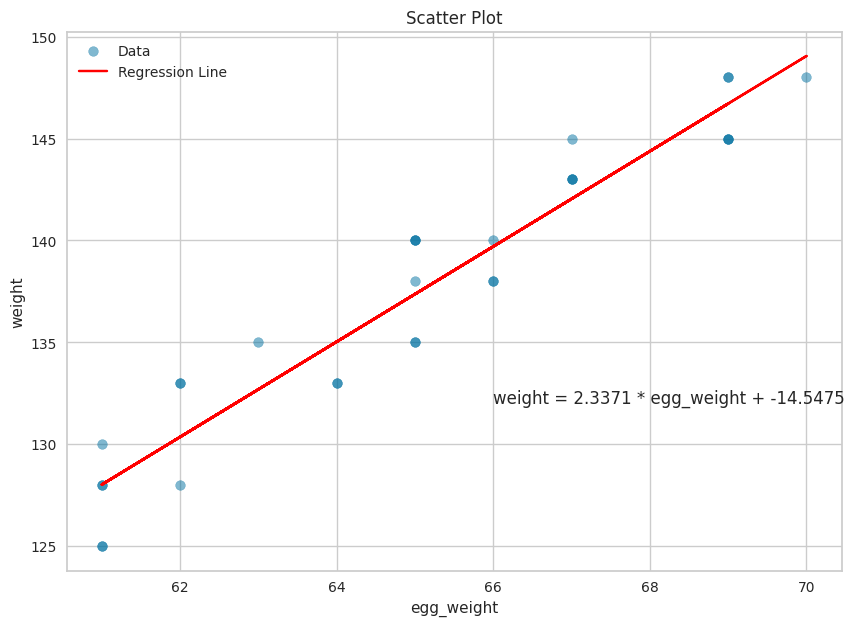

In [ ]:
# 실제 값(점)과 모델이 예측한 값(선)을 비교해서 보여준다, 실제값과 예측값을 한 그래프에 그려서 모델 성능을 눈으로 확인하는 코드
plt.figure(figsize=(10, 7)) # 그래프 크게 보기 (가로 10, 세로 7)
plt.scatter(w2['egg_weight'], w2['weight'], alpha=0.5, label='Data') # 실제 데이터 (산점도),x: 계란 무게 y: 실제 병아리 무게,점으로 표시
plt.plot(w2['egg_weight'], y_pred, color='red', label='Regression Line') # 회귀선 (예측값) -predict 결과를 사용한 것
plt.text(66, 132, f'weight = {coef:.4f} * egg_weight + {intercept:.4f}', fontsize=12) # 그래프에 공식 출력
plt.title('Scatter Plot') # 제목
plt.xlabel('egg_weight') # 축이름
plt.ylabel('weight')
plt.legend() #Data / Regression Line 표시
plt.show()

## 스탯츠모델스 통계분석 방식 선형회귀 1-2
#### 다중 회귀 분석
#### import statsmodels.formula.api as smf              


In [ ]:
# 입력값과 결과값 사이의 관계를 직선/회귀식으로 학습
# 여러 가지 요소(계란 무게, 먹이량, 활동량)를 함께 이용하여 병아리 무게를 예측
                           #  종속변수 - 독립변수 , 여러개면 + 로 연결 (먹이, 활동량)
                           #    y,       x1,       x2,     x3
model2 = smf.ols(formula = 'weight ~ egg_weight + food + movement', data = w2)  # 모델구축

result2 = model2.fit()  # 데이터를 이용하여 회귀계수(기울기와 절편)를 학습

result2.summary() # 회귀분석 결과 확인(R², coef, p-value 등), 성적표

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 weight   R-squared:                       0.948
Model:                            OLS   Adj. R-squared:                  0.942
Method:                 Least Squares   F-statistic:                     157.7
Date:                Mon, 07 Sep 2026   Prob (F-statistic):           8.46e-17
Time:                        06:37:08   Log-Likelihood:                -56.008
No. Observations:                  30   AIC:                             120.0
Df Residuals:                      26   BIC:                             125.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9748      8.587      0.346      0.732     -14.676      20.626
egg_weight     1.7763      0.195      9.117      0.000       1.376       2.177
food           1.5847      0.405      3.915      0.001       0.753       2.417
movement      -0.0087      0.017     -0.522      0.606      -0.043       0.026
==============================================================================
Omnibus:                        1.993   Durbin-Watson:                   2.030
Prob(Omnibus):                  0.369   Jarque-Bera (JB):                1.746
Skew:                          -0.480   Prob(JB):                        0.418
Kurtosis:                       2.311   Cond. No.                     4.31e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 4.31e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### 다중선형회귀 결과 해석
##### 계란 무게 + 먹이량 + 활동량을 함께 사용해서 병아리 무게를 예측한 결과
| 꼭 볼 값                |          결과 | 쉽게 해석                                           |
| -------------------- | ----------: | ----------------------------------------------- |
| **R-squared**        |   **0.948** | 세 변수를 이용해 병아리 몸무게의 변화를 **약 94.8% 설명**           |
| `egg_weight` coef    |  **1.7763** | 다른 조건이 같을 때 계란 무게가 1 증가하면 예측 몸무게가 약 **1.78 증가** |
| `egg_weight` p-value |   **0.000** | 0.05보다 작음 → 병아리 무게와 **의미 있는 관계가 있음**            |
| `food` coef          |  **1.5847** | 다른 조건이 같을 때 먹이가 1 증가하면 예측 몸무게가 약 **1.58 증가**    |
| `food` p-value       |   **0.001** | 0.05보다 작음 → 병아리 무게와 **의미 있는 관계가 있음**            |
| `movement` coef      | **-0.0087** | 다른 조건이 같을 때 활동량이 1 증가하면 예측 몸무게가 약 **0.009 감소**  |
| `movement` p-value   |   **0.606** | 0.05보다 큼 → 병아리 무게와 **뚜렷한 관계가 있다고 보기 어려움**       |

```
병아리 몸무게를 예측할 때 계란 무게와 먹이량은 의미 있는 변수였지만, 활동량은 이 데이터에서는 뚜렷한 관계가 확인되지 않았다.

p-value < 0.05 → 의미 있는 관계가 있다고 판단
p-value > 0.05 → 의미 있는 관계가 있다고 보기 어려움

coef = 얼마나 증가/감소하는가
p-value = 그 관계를 의미 있다고 볼 수 있는가

p-value < 0.05 → 처음에 세운 가정을 버린다.
| 검사          | 처음 가정        | p < 0.05가 나오면          |
| ----------- | ------------ | ---------------------- |
| **Shapiro** | 정규분포다        | 가정을 버림 → **정규분포가 아니다** |
| **t-test**  | 두 평균이 같다     | 가정을 버림 → **두 평균이 다르다** |
| **회귀분석**    | 두 변수는 관계가 없다 | 가정을 버림 → **관계가 있다**    |


```
R-squared → 모델이 얼마나 설명하는가?

coef      → x가 1 증가하면 y가 얼마나 변하는가?

p-value   → 그 변수가 통계적으로 의미가 있는가?
             < 0.05 → 유의함
             > 0.05 → 유의하다고 보기 어려움

p < 0.05
   ↓
처음 가정을 버린다!


p-value < 0.05 → 처음 가정을 버린다(기각)
p-value > 0.05 → 처음 가정을 버리지 못한다

In [ ]:
# R-squared : 94.8% 설명 가능 → 매우 좋은 모델
"""
 coef - 기울기
 weight = 1.7763 * egg_weight
       + 1.5847 * food
       - 0.0087 * movement
       + 2.9748
"""
# P값은 이 결과가 우연일 확률 p = 0.01  우연일 확률 1% → 거의 확실 → 사용,0.05는 우연일 가능성을 5%까지만 인정하겠다는 약속
# P>|t|	[0.025	0.975] 이 변수 쓸까? 말까?” 판단, 0.05보다 작다 → 사용 (중요), 0.05보다 크다 → 버림 (의미 없음)

# 병아리 무게는 계란무게 + 먹이가 중요하고, 움직임은 영향 없다
# 설명력 높은 좋은 모델이고, 중요한 변수는 egg_weight와 food이다

In [ ]:
# 입력값과 결과값 사이의 관계를 직선/회귀식으로 학습
                           #  y   ,       x1  , x2
model2 = smf.ols(formula = 'weight ~ egg_weight + food ', data = w2) #다중회귀 모델 생성 (병아리무게 = 계란무게 + 먹이 영향)

result2 = model2.fit() #모델 학습 (데이터로 공식 계산)

result2.summary() #결과 출력 (계수, p값, 설명력 확인)

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 weight   R-squared:                       0.947
Model:                            OLS   Adj. R-squared:                  0.943
Method:                 Least Squares   F-statistic:                     243.0
Date:                Mon, 07 Sep 2026   Prob (F-statistic):           5.44e-18
Time:                        06:37:08   Log-Likelihood:                -56.164
No. Observations:                  30   AIC:                             118.3
Df Residuals:                      27   BIC:                             122.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      3.6638      8.370      0.438      0.665     -13.510      20.837
egg_weight     1.7453      0.183      9.536      0.000       1.370       2.121
food           1.5955      0.399      4.001      0.000       0.777       2.414
==============================================================================
Omnibus:                        2.302   Durbin-Watson:                   2.103
Prob(Omnibus):                  0.316   Jarque-Bera (JB):                1.940
Skew:                          -0.502   Prob(JB):                        0.379
Kurtosis:                       2.263   Cond. No.                     1.84e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.84e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

# 사이킷런(scikit-learn)의 선형회귀 모델2-2
##### 사이킷런의 LinearRegression()에는 statsmodels처럼 .summary()가 없다.

In [ ]:
x = w2[["egg_weight", "food"]] #  모델에 넣을 입력 데이터, 계란무게 + 먹이, 이걸 보고 예측하겠다,재료(x): 계란, 먹이 / 표 형태 (2차원)
y = w2["weight"] # 결과(y): 병아리 무게

In [ ]:
# [수업 포인트] 입력값과 결과값 사이의 관계를 직선/회귀식으로 학습
# 모델 생성 및 학습
model3 = LinearRegression()
model3.fit(x, y)

LinearRegression()

In [ ]:
print("Intercept (절편):", model3.intercept_)
print("Coefficients (회귀 계수):", model3.coef_)

Intercept (절편): 3.663849948713022
Coefficients (회귀 계수): [1.74532311 1.5954672 ]


# 성적표

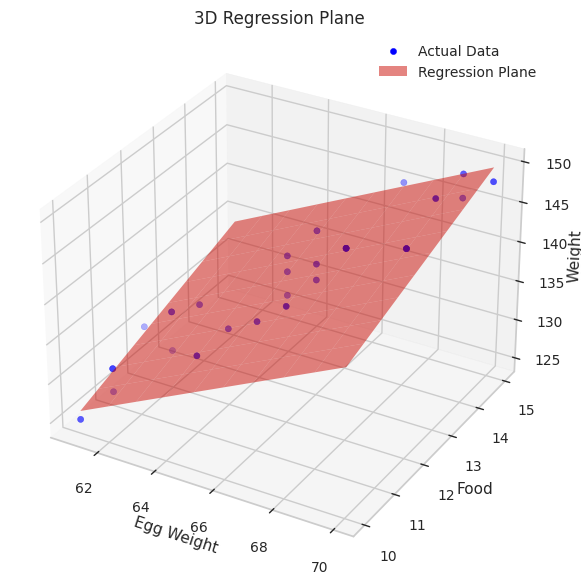

In [ ]:
# 3D 그래프 준비
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(w2["egg_weight"], w2["food"], w2["weight"], c='blue', label='Actual Data')

x_range = np.linspace(w2["egg_weight"].min(), w2["egg_weight"].max(), 10)
y_range = np.linspace(w2["food"].min(), w2["food"].max(), 10)
X_range, Y_range = np.meshgrid(x_range, y_range)

Z_range = model3.intercept_ + model3.coef_[0] * X_range + model3.coef_[1] * Y_range

ax.plot_surface(X_range, Y_range, Z_range, color='r', alpha=0.5, label='Regression Plane')

ax.set_xlabel("Egg Weight")
ax.set_ylabel("Food")
ax.set_zlabel("Weight")
ax.set_title("3D Regression Plane")
ax.legend()
plt.show()

사이킷런의 LinearRegression()에는 statsmodels처럼 .summary()가 없다.
```
사이킷런에서는

model3 = LinearRegression()
model3.fit(x, y)

# 기울기
print(model3.coef_)

# 절편
print(model3.intercept_)

# R²(결정계수)
print(model3.score(x, y))

# 예측
model3.predict(x_new)

```


# 차이
|         | statsmodels          | scikit-learn         |
| ------- | -------------------- | -------------------- |
| 모델      | `smf.ols()`          | `LinearRegression()` |
| 학습      | `.fit()`             | `.fit()`             |
| 결과표     | **`.summary()` 있음**  | **없음**               |
| 기울기     | summary의 `coef`      | `.coef_`             |
| 절편      | summary의 `Intercept` | `.intercept_`        |
| R²      | summary의 `R-squared` | `.score(x, y)`       |
| p-value | **제공함**              | **기본 제공 안 함**        |
| 주목적     | **통계적 해석**           | **학습·예측**            |


### statsmodels → 분석 결과를 자세히 보고 싶을 때
### scikit-learn → 데이터를 학습시키고 새로운 값을 예측할 때
##### 실제 머신러닝 수업으로 넘어가면 scikit-learn의 fit() → predict() → 평가 흐름이 더 중요해진다.